# PART 0 — نمایش ویژهٔ هوش مصنوعی

**بازیِ حیوانات.** ماشین فقط ۸ حیوان با برچسب می‌بیند؛ بعد خودش یک خط می‌کشد و به حیواناتی که هرگز ندیده جواب می‌دهد.


In [ ]:
# DEMO: the animal game — the machine learns one rule from 8 examples
import pandas as pd
from sklearn.tree import DecisionTreeClassifier
import matplotlib.pyplot as plt

# stage 1: everything the machine sees — 8 animals, two numbers and one label each
print("--- stage 1 - the table ---")
animals = pd.DataFrame({
    "weight": [4.5, 3.0, 6.0, 5.0, 22, 32, 28, 38],      # kg
    "ear_length": [5, 7, 4, 6, 9, 12, 11, 13],            # cm
    "label": ["cat", "cat", "cat", "cat", "dog", "dog", "dog", "dog"],
}, index=["persian", "siamese", "garfield", "chartreux",
          "bulldog", "german", "golden", "doberman"])
print("everything the machine sees (just 8 rows):")
print(animals, "\n")

# stage 2: learn — the machine finds the rule itself (quietly!)
model = DecisionTreeClassifier(max_depth=1, random_state=42)
model.fit(animals[["weight", "ear_length"]], animals["label"])

# stage 3: see the line the machine drew — no human drew it
print("--- stage 3 - the machine's line ---")
plt.figure(figsize=(8, 4))
cats = animals[animals["label"] == "cat"]; dogs = animals[animals["label"] == "dog"]
plt.scatter(cats["weight"], cats["ear_length"], c="steelblue", s=130, label="cat")
plt.scatter(dogs["weight"], dogs["ear_length"], c="darkorange", s=130, label="dog")
plt.axvline(14, color="crimson", lw=2, ls="--")
plt.text(15, 12.2, "the line the machine drew itself", color="crimson")
plt.xlabel("weight (kg)"); plt.ylabel("ear length (cm)"); plt.legend()
plt.show()

# stage 4: exam! animals the machine has never seen
print("--- stage 4 - exam with unseen animals ---")
new_animals = pd.DataFrame({
    "weight": [35, 7, 2, 3000],
    "ear_length": [10, 5, 10, 20],
}, index=["wolf", "neighbor cat", "puppy", "elephant"])
print("the machine's answers for animals it had never seen:")
answers = model.predict(new_animals[["weight", "ear_length"]])
for name, ans in zip(new_animals.index, answers):
    print(f"  {name:12} -> {ans}")

# the whole secret of stage 2 was one question: weight <= 14 kg?
print("\nthe machine's whole secret was ONE question: weight <= 14 kg?")


# جلسهٔ ۱ — یادگیری ماشین چیست؟
## روز اول — تو یک هوش مصنوعی می‌سازی

**هدف امروز تو:** *«تا پایان امروز، تو می‌توانی یک مدل یادگیری ماشین آموزش بدهی و به خانواده‌ات نشان بدهی.»*

**تحویل امشب:** یک مخزن گیت‌هاب با این نت‌بوک + مدلی که جواب می‌دهد: **«آیا من در تایتانیک زنده می‌ماندم؟»**

---

# PART A — جلسهٔ تدریس
*(این بخش را با هم در کلاس پر می‌کنیم)*


In [2]:
# COURSE SETUP — identical in every session. Just run it. (5 seconds)
%matplotlib inline
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier, plot_tree

plt.rcParams["figure.figsize"] = (8, 4)
print("Setup OK — let's build some AI.")


Setup OK — let's build some AI.


## A1 — بازی میوه: ویژگی‌ها و برچسب‌ها

هر نمونهٔ یادگیری ماشین با **ویژگی (Feature)** — یعنی سرنخ — و یک **برچسب (Label)** — یعنی پاسخ — توصیف می‌شود.
هر سطر (ویژگی‌ها + برچسب) یک **نمونه (Example)** است.

سلول را اجرا کن و بازی کن: ستون پاسخ را بپوشان و فقط از سرنخ‌ها میوه را حدس بزن.


In [3]:
fruits = pd.DataFrame({
    "color":   ["red", "yellow", "purple", "yellow", "red", "green"],
    "size":    ["medium", "long", "small", "medium", "round", "medium"],
    "texture": ["smooth", "smooth", "wrinkly", "curved", "smooth", "smooth"],
    "fruit":   ["apple", "banana", "grape", "banana", "apple", "apple"],
})
fruits


,color,size,texture,fruit
0,red,medium,smooth,apple
1,yellow,long,smooth,banana
2,purple,small,wrinkly,grape
3,yellow,medium,curved,banana
4,red,round,smooth,apple
5,green,medium,smooth,apple


## A2 — کدام ویژگی مهم‌تر است؟

به جدول نگاه کن. **کدام سرنخ** برای حدس زدن میوه مفیدتر است: `color`، `size` یا `texture`؟

یک دقیقه بحث کن، بعد حدست را پایین بنویس. *(هنوز جواب غلطی وجود ندارد — جلسهٔ ۹ یاد می‌گیریم این را حساب کنیم!)*


In [4]:
most_useful_feature = "color"   # <-- change to your guess: "color", "size" or "texture"
print(f"I think '{most_useful_feature}' is the most useful clue.")


I think 'color' is the most useful clue.


## A3 — یادگیری نظارت‌شده: پنهان‌کردن پاسخ

یادگیری نظارت‌شده (Supervised Learning) = یادگیری از نمونه‌هایی **که پاسخ دارند**.
مدل جدول کامل را درس می‌خواند... بعد **برچسب را پنهان می‌کنیم** و با نمونه‌های جدید ازش امتحان می‌گیریم.


In [5]:
study_table = fruits.copy()          # what the model studies WITH answers
quiz_table = fruits.drop(columns=["fruit"])  # what the model sees at quiz time

print("study (features + label):")
display(study_table.head(3))
print("quiz (features only - the label is hidden!):")
display(quiz_table.head(3))


study (features + label):


,color,size,texture,fruit
0,red,medium,smooth,apple
1,yellow,long,smooth,banana
2,purple,small,wrinkly,grape


quiz (features only - the label is hidden!):


,color,size,texture
0,red,medium,smooth
1,yellow,long,smooth
2,purple,small,wrinkly


## A4 — تایتانیک: ۸۹۱ مسافر

هر سطر یک زندگی است. هر ستون یک سرنخ. برچسب `survived` است (۱ = زنده ماند، ۰ = مرد).

«تنها» ریسکِ دیتای واقعی: بعضی سطرها اطلاعات ناقص دارند — پایین می‌بینی که فقط سطرهای کامل به مدل می‌رسند.


In [6]:
# the dataset lives in the course assets folder; if missing, it is fetched fresh.
for _src in ("assets/titanic.csv", "../assets/titanic.csv",
             "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"):
    try:
        titanic = pd.read_csv(_src)
        break
    except Exception:
        continue
titanic = titanic.rename(columns=str.lower)
titanic = titanic[["survived", "pclass", "sex", "age", "fare", "embarked"]].dropna()
print(f"out of 891 passengers, {len(titanic)} have complete data; only these train the model.")
titanic.head()


out of 891 passengers, 712 have complete data; only these train the model.


,survived,pclass,sex,age,fare,embarked
0,0,3,male,22.0,7.2500,S
1,1,1,female,38.0,71.2833,C
2,1,3,female,26.0,7.9250,S
3,1,1,female,35.0,53.1000,S
4,0,3,male,35.0,8.0500,S


## A5 — داده به‌صورت عکس: چه کسی زنده ماند؟

*همیشه قبل از هر کاری، داده‌ات را ببین.*


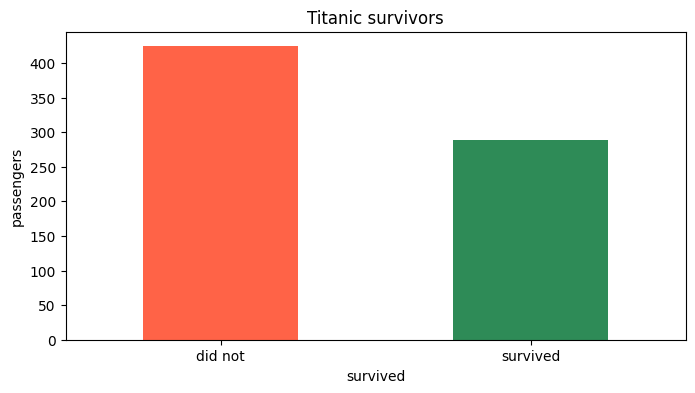

In [7]:
titanic["survived"].map({1: "survived", 0: "did not"}).value_counts().plot(
    kind="bar", color=["tomato", "seagreen"], rot=0)
plt.title("Titanic survivors"); plt.ylabel("passengers")
plt.show()


## A6 — دو نمودار ضربهٔ نهایی


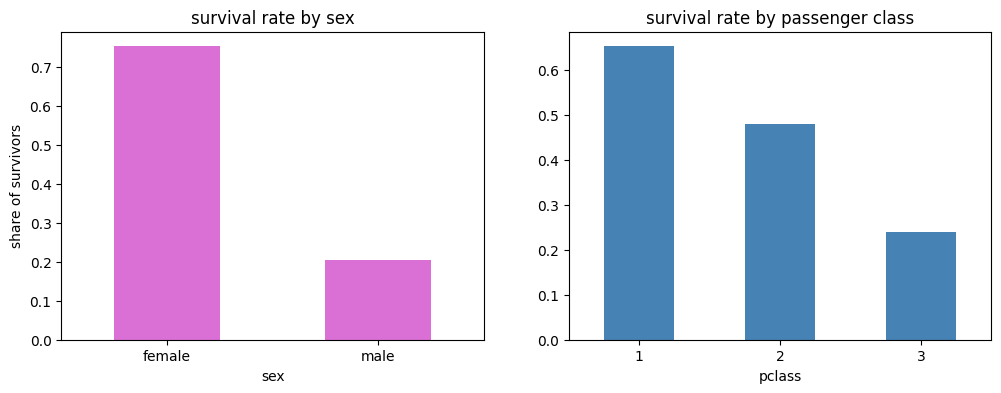

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
titanic.groupby("sex")["survived"].mean().plot(kind="bar", ax=axes[0], color="orchid", rot=0)
axes[0].set_title("survival rate by sex"); axes[0].set_ylabel("share of survivors")
titanic.groupby("pclass")["survived"].mean().plot(kind="bar", ax=axes[1], color="steelblue", rot=0)
axes[1].set_title("survival rate by passenger class")
plt.show()
# being a class-1 woman in 1912 was nearly a survival ticket — look: 75% vs 20%!


## A7 تا A9 — لحظهٔ جادویی: ساخت هوش مصنوعی در ۳ خط

با من تایپ کن. سه خط. همین یک هوش مصنوعی کامل است.


In [9]:
# line zero (not magic, just prep): turn the clues into numbers the model understands
X = titanic[["pclass", "age", "fare"]].copy()
X["is_female"] = (titanic["sex"] == "female").astype(int)
y = titanic["survived"]
X.head(3)


,pclass,age,fare,is_female
0,3,22.0,7.2500,0
1,1,38.0,71.2833,1
2,3,26.0,7.9250,1


In [10]:
# A8 — the three magic lines. Count one two three, everyone shout: fit!
# "model" means the model: the student that reads solved examples
model = DecisionTreeClassifier(max_depth=3, random_state=42)  # 1. pick a student (the model)
model.fit(X, y)                                               # 2. let it study
print(f"done. the model just read {len(X)} lives in under a second.")


done. the model just read 712 lives in under a second.


does not survive


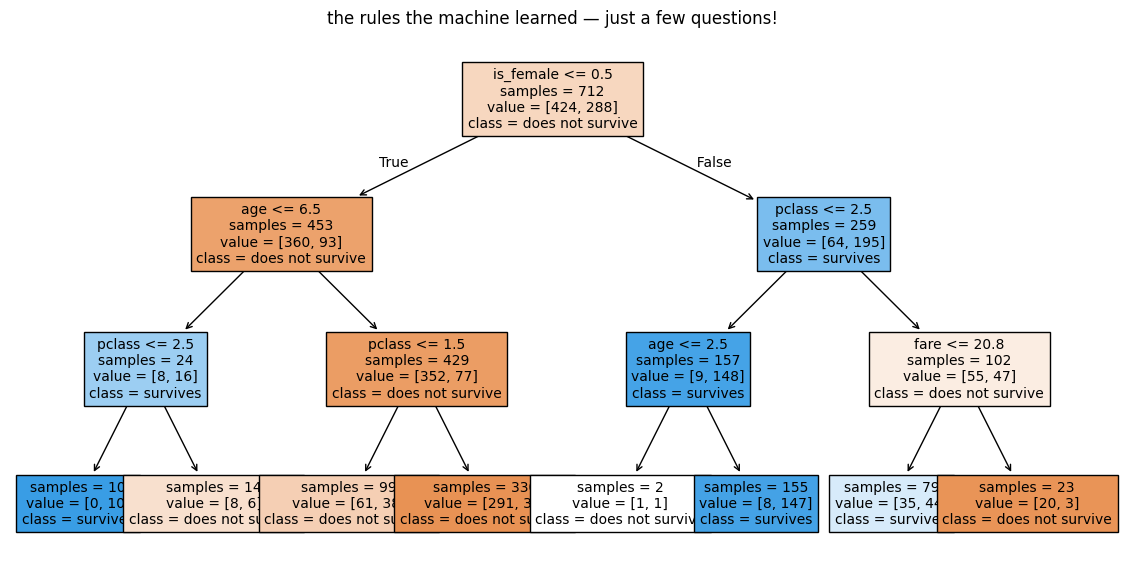

In [11]:
# A9 — ask it: would YOU have survived?
me = pd.DataFrame([{"pclass": 2, "age": 13, "fare": 30, "is_female": 0}])  # <-- make this one yourself!
verdict = model.predict(me)[0]
print("survives" if verdict == 1 else "does not survive")

# and look — the rules it found are just a few questions. You could have drawn them yourself.
plt.figure(figsize=(14, 7))
plot_tree(model, feature_names=list(X.columns),
          class_names=["does not survive", "survives"],
          filled=True, fontsize=10, impurity=False)
plt.title("the rules the machine learned — just a few questions!")
plt.show()


---

# PART B — تمرین‌های خانه
**مهلت: قبل از جلسهٔ حل مسئله.** پاسخ‌ها را همین‌جا در همین سلول‌ها بنویس. (حدود ۲۰ تا ۳۰ دقیقه طول می‌کشد.)
هر وقت خواستی خودت را نمره بده: `python judge/run.py s01_notebook.ipynb`
اولین اجرا همهٔ تمرین‌ها را قرمز نشان می‌دهد — عادی است! آن را با پاسخ‌های خودت سبز کن.

**چه چیزی باید یاد بگیری:** این تمرین‌ها مطمئن می‌شوند که خودت، تنها، می‌توانی دیتاست بسازی،
مدل آموزش بدهی و پیش‌بینی کنی.


## تمرین B1 — کارآگاه ویژگی‌ها (۱ نمره)

یک دوست می‌خواهد **قبولی یک دانش‌آموز در آزمون** را پیش‌بینی کند و این ویژگی‌ها را پیشنهاد می‌دهد:

`["name", "hours_studied", "favorite_color", "previous_score", "shoe_size"]`

فقط ویژگی‌هایی را که واقعاً می‌توانند به پیش‌بینی قبولی کمک کنند، به‌صورت یک **لیست** پایتونی بنویس.
(راهنما: آیا مدل از اسمِ کسی چیزی مفید یاد می‌گیرد؟)


In [12]:
# your answer here — uncomment the line below and complete it yourself:
# B1_good_features = ["..."]   # <-- only clues that really predict admission


## تمرین B2 — دیتاست خودت را بساز (۱ نمره)

حالا تو معلمی. یک دیتاست کوچک (یک DataFrame پانداسی) از **حداقل ۴ حیوان** بساز
با ویژگی‌های `["size", "can_fly"]` و برچسب `"animal"`. شرایط:

- دقیقاً همین ۳ ستون،
- حداقل ۴ سطر، هر کدام یک حیوان متفاوت،
- `size` یکی از `"small"`، `"medium"`، `"large"` باشد و `can_fly` عدد `0` یا `1`.


In [13]:
# your answer here — uncomment the pattern below and fill it with YOUR animals:
# B2_animals = pd.DataFrame({
#     "size":    ["small", "large", "medium", "small"],   # only: "small" or "medium" or "large"
#     "can_fly": [0, 0, 0, 1],                            # only 0 or 1
#     "animal":  ["cat", "elephant", "dog", "sparrow"],   # 4 different animals (or more)
# })


## تمرین B3 — سه خط جادویی (۱ نمره)

برای آموزش یک درخت تصمیم روی دیتاست حیواناتِ خودت، سه جای `...` را کامل کن
(اگر تمرین B2 را نکرده‌ای، اول برگرد سراغش — این سلول به آن نیاز دارد).


In [14]:
if "B2_animals" not in dir():
    print("finish problem B2 first — this cell needs your dataset (B2_animals).")
else:
    B2_animals_num = B2_animals.copy()
    B2_animals_num["size_num"] = B2_animals_num["size"].map({"small": 0, "medium": 1, "large": 2})

    B3_X = B2_animals_num[["size_num", "can_fly"]]     # features
    B3_y = B2_animals_num["animal"]                    # label

    B3_model = ...      # TODO: build a DecisionTreeClassifier (random_state=42)
    ...                 # TODO: train it on B3_X and B3_y — the fit command
    B3_prediction = ... # TODO: ask with .predict: medium size (size_num=1), cannot fly (can_fly=0) — which animal?
    print("the model says the medium, non-flying animal is:", B3_prediction)


finish problem B2 first — this cell needs your dataset (B2_animals).


## تمرین B4 — پیش‌بینی‌گر بقا (۱ نمره)

مدل تایتانیکِ خودت را آموزش بده (مثل کلاس، با `max_depth=3` و `random_state=42`)
و بقا را برای این مسافر پیش‌بینی کن: **کلاس ۳، پسر ۱۲ ساله، کرایهٔ ۷.۵.**

بعد جواب بده: او زنده ماند؟ عدد `1` (زنده ماند) یا `0` (نماند) را در `B4_answer` بگذار.


In [15]:
# data already loaded (titanic). Like cell A7, build X and y exactly:
B4_X = ...   # TODO: the same 4 columns as A7 (pclass, age, fare, is_female)
B4_y = ...   # TODO: the answer column (survived)

B4_model = ...   # TODO: build (max_depth=3, random_state=42) and train on B4_X and B4_y

new_passenger = pd.DataFrame([{"pclass": 3, "age": 12, "fare": 7.5, "is_female": 0}])
B4_answer = ...  # TODO: int( model prediction for the new passenger ) — must be 0 or 1


---

# تحویل بده!

وقتی هر چهار تمرین از داوری سربلند بیرون آمد:
1. این نت‌بوک را ذخیره کن.
2. آن را در مخزن گیت‌هاب دوره‌ات commit کن — در پوشهٔ جلسه این سه دستور:
   `git add .` ← `git commit -m "S1: my first model"` ← `git push`
3. به خانواده‌ات نشان بده: *«امروز یک هوش مصنوعی ساختم.»* — چون واقعاً ساختی.


---

# PART C — جلسهٔ حل مسئله
*(اول تمرین‌های خانه را زنده حل می‌کنیم — بعد این‌ها را)*


## C1 — موتور خیال

**مسافرهای خودت را اختراع کن** (هر کلاس، سن، کرایه و جنسیتی که دوست داری) و ببین مدل چه می‌گوید.
می‌توانی مسافری پیدا کنی که مدل در او *اشتباه* کند؟ می‌توانی مدل را بشکنی؟


In [16]:
my_passengers = pd.DataFrame([
    {"pclass": 1, "age": 40, "fare": 500, "is_female": 1},
    {"pclass": 3, "age": 30, "fare": 5,  "is_female": 0},
    # add your own rows here!
])
preds = model.predict(my_passengers)
for i, p in enumerate(preds):
    print(f"passenger {i+1}: {'survives' if p else 'does not survive'}")


passenger 1: survives
passenger 2: does not survive


## C2 — انسان را شکست بده

قبل از اجرای سلول بعدی، بقا هر یک از این ۵ مسافر را خودت حدس بزن.
۵ حدست را بنویس (مثلاً `"01100"`)، بعد اجرا کن. **می‌توانی از ماشین جلو بزنی؟**


In [17]:
challenge = pd.DataFrame([
    {"pclass": 1, "age": 35, "fare": 80,  "is_female": 1},
    {"pclass": 2, "age": 29, "fare": 26,  "is_female": 0},
    {"pclass": 3, "age": 21, "fare": 7,   "is_female": 0},
    {"pclass": 1, "age": 60, "fare": 90,  "is_female": 0},
    {"pclass": 3, "age": 6,  "fare": 12,  "is_female": 1},
])
my_guesses = "00000"  # <-- your 5 guesses, one character per passenger, before running predict
machine = "".join(str(p) for p in model.predict(challenge))
print("you:    ", my_guesses)
print("machine:", machine)
score = sum(a == b for a, b in zip(my_guesses, machine))
print(f"you agreed with the machine {score}/5 times.")


you:     00000
machine: 10001
you agreed with the machine 3/5 times.


## C3 — بحث: دانشِ ماشین کجا زندگی می‌کند؟

دوباره به عکس درخت در سلول A9 نگاه کن. مدل هیچ‌وقت کتاب تاریخ نخوانده.
هیچ‌وقت از کوه یخ نشنیده. **«دانش» او از کجا آمده؟**

*(جوابت را به جمع‌بندی بیاور — این، بذرِ همهٔ کارهای جلسهٔ ۲ است.)*
